[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_paper_ablation/BA_L5_paper_ablation.ipynb)

# BA_L5_paper_ablation: Ablation of the Depeg Forecast Model (Published Table)

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Deterioration of the quantile (pinball) loss at the 1% and 99% levels when one component of the distributional depeg forecast model is removed (twCRPS loss, GPD tails, non-Gaussian head, sparsity, liquidity features, covariates); values from Table 4 of Chaffard, Gaman, Staures, Ginavar, Jheng, Hardle and Pele (2026), Onchain Monitoring of Stablecoin Depeg Risk, working paper.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

Source: Table 4 of Chaffard, Găman, Staures, Ginavar, Jheng, Härdle & Pele (2026), *Onchain Monitoring of Stablecoin Depeg Risk*, working paper. The values are typed in below; nothing is estimated here.

The ablation removes one component of the distributional forecast model at a time and reports how much worse the quantile (pinball) loss (QL) becomes at the 1% and 99% levels, in percent of the full model's loss:

- no twCRPS: trained without the threshold-weighted continuous ranked probability score;
- no GPD tails: without the generalised Pareto tails;
- Gaussian: a Gaussian output distribution instead of the spline body with GPD tails;
- no sparsity, no liquidity features, no covariates: without the sparsity penalty, without the liquidity features, without any covariate.

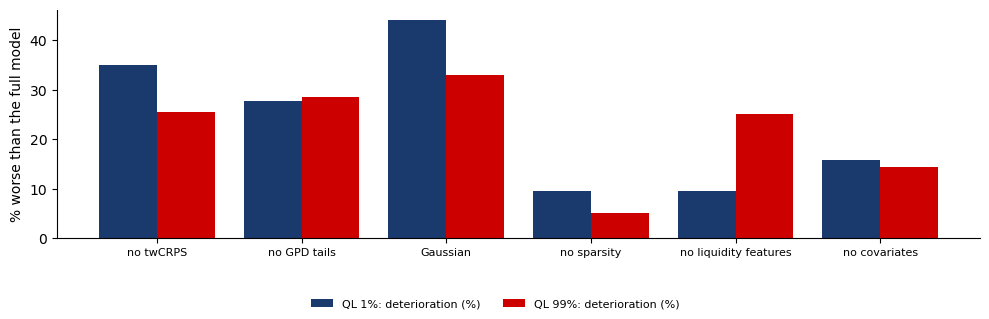

In [5]:
T4 = {'no twCRPS': (-35.0, -25.6), 'no GPD tails': (-27.8, -28.5), 'Gaussian': (-44.0, -33.0), 'no sparsity': (-9.6, -5.1),
      'no liquidity features': (-9.5, -25.0), 'no covariates': (-15.8, -14.4)}       # change of QL 1% and QL 99% (%), Table 4
nm = list(T4); a = np.arange(len(nm))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(a - 0.2, [-T4[k][0] for k in nm], width=0.4, color=BLUE, label='QL 1%: deterioration (%)')
ax.bar(a + 0.2, [-T4[k][1] for k in nm], width=0.4, color=RED, label='QL 99%: deterioration (%)')
ax.set_xticks(a); ax.set_xticklabels(nm, fontsize=8); ax.set_ylabel('% worse than the full model')
save(fig, 'ba_l5_paper_ablation', 0.13, ncol=2)

## Key numbers (Table 4 of the paper)

In [6]:
pd.DataFrame({k: {'QL 1%: deterioration (%)': -T4[k][0], 'QL 99%: deterioration (%)': -T4[k][1]} for k in nm}).T

,QL 1%: deterioration (%),QL 99%: deterioration (%)
no twCRPS,35.0,25.6
no GPD tails,27.8,28.5
Gaussian,44.0,33.0
no sparsity,9.6,5.1
no liquidity features,9.5,25.0
no covariates,15.8,14.4


**How to read it:** a Gaussian output loses 44% at the 1% quantile; dropping the liquidity features costs 25% at the 99% quantile, more than dropping all covariates.